# Modelagem Preditiva 

## Objetivo

Este notebook tem como objetivo desenvolver modelos de
classificação para prever a aprovação ou reprovação dos
estudantes, considerando as características pessoais,
familiares, sociais, comportamentais e escolares, além
das notas obtidas nos dois primeiros períodos.


#### 1 - Bibliotecas 

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

#### 2 - Carregamentos dos dados

In [2]:
caminho = Path("../data/raw/student-mat.csv")

df = pd.read_csv(caminho)

print(f"Dimensões da base: {df.shape}")
df.head()

Dimensões da base: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
#Checagem inicial

print("Total de registros:", df.shape[0])
print("Total de variáveis:", df.shape[1])

print("\nValores ausentes:")
print(df.isnull().sum().sum())

print("\nDuplicatas:")
print(df.duplicated().sum())

Total de registros: 395
Total de variáveis: 33

Valores ausentes:
0

Duplicatas:
0


#### 3 - Selecionando variáveis 

In [4]:
# 0 = Reprovado e 1 = Aprovado
df["resultado"] = (df["G3"] >= 10).astype(int)

print(df["resultado"].value_counts())
print((df["resultado"].value_counts(normalize=True) * 100).round(2))

resultado
1    265
0    130
Name: count, dtype: int64
resultado
1    67.09
0    32.91
Name: proportion, dtype: float64


In [5]:
# Variável-alvo
y = df["resultado"]

# Variáveis explicativas
X = df.drop(
    columns=[
        "G3",
        "resultado",
        "resultado_final",
        "desempenho"
    ],
    errors="ignore"
)

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)


Dimensões de X: (395, 32)
Dimensões de y: (395,)


#### 3.1 - Divisão de treino e teste

In [6]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)

print("\nDistribuição das classes no treino:")
print(y_treino.value_counts(normalize=True).round(3))

print("\nDistribuição das classes no teste:")
print(y_teste.value_counts(normalize=True).round(3))

Treino: (316, 32)
Teste: (79, 32)

Distribuição das classes no treino:
resultado
1    0.671
0    0.329
Name: proportion, dtype: float64

Distribuição das classes no teste:
resultado
1    0.671
0    0.329
Name: proportion, dtype: float64


In [7]:
# Identificação dos tipos de variáveis
colunas_numericas = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

colunas_categoricas = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Variáveis numéricas:", len(colunas_numericas))
print("Variáveis categóricas:", len(colunas_categoricas))

print("\nColunas numéricas:")
print(colunas_numericas)

print("\nColunas categóricas:")
print(colunas_categoricas)

Variáveis numéricas: 15
Variáveis categóricas: 17

Colunas numéricas:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Colunas categóricas:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\felip\AppData\Local\Temp\ipykernel_19188\3782592063.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = X.select_dtypes(


#### 4 - Pipeline 


In [8]:
# Transformação das variáveis numéricas
transformador_numerico = StandardScaler()

# Transformação das variáveis categóricas
transformador_categorico = OneHotEncoder(
    handle_unknown="ignore"
)

# Combinação dos transformadores
preprocessador = ColumnTransformer(
    transformers=[
        ("num", transformador_numerico, colunas_numericas),
        ("cat", transformador_categorico, colunas_categoricas)
    ]
)


#### 5 - Modelo e métricas

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    make_scorer
)



In [ ]:

# Seleção de modelos
modelos = {
    "Regressão Logística": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Árvore de Decisão": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}



In [11]:
# Cross validation 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",

    "precision_reprovado": make_scorer(
        precision_score,
        pos_label=0,
        zero_division=0
    ),

    "recall_reprovado": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    ),

    "f1_reprovado": make_scorer(
        f1_score,
        pos_label=0,
        zero_division=0
    )
}

In [12]:
# Avaliando os modelos 
resultados_cv = []

for nome, modelo in modelos.items():

    pipeline = Pipeline(steps=[
        ("preprocessamento", preprocessador),
        ("modelo", modelo)
    ])

    scores = cross_validate(
        pipeline,
        X_treino,
        y_treino,
        cv=cv,
        scoring=metricas,
        n_jobs=-1
    )

    resultados_cv.append({
        "Modelo": nome,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1 Macro": scores["test_f1_macro"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Precisão Reprovados": scores["test_precision_reprovado"].mean(),
        "Recall Reprovados": scores["test_recall_reprovado"].mean(),
        "F1 Reprovados": scores["test_f1_reprovado"].mean()
    })

df_resultados_cv = pd.DataFrame(resultados_cv)

df_resultados_cv.round(4)

,Modelo,Accuracy,F1 Macro,Balanced Accuracy,Precisão Reprovados,Recall Reprovados,F1 Reprovados
0,Regressão Logística,0.9081,0.8981,0.9066,0.8372,0.9029,0.8665
1,Árvore de Decisão,0.9113,0.8986,0.8920,0.8982,0.8362,0.8631
2,Random Forest,0.9272,0.9194,0.9283,0.8618,0.9324,0.8945


### Insights — Validação Cruzada

A inclusão das notas G1 e G2 proporcionou uma melhora expressiva no desempenho preditivo dos três algoritmos avaliados.

A Random Forest apresentou o melhor desempenho geral, alcançando 92,72% de Accuracy, 91,94% de F1 Macro e 92,83% de Balanced Accuracy. Além disso, obteve o maior Recall para a classe dos estudantes reprovados, com 93,24%.

A Regressão Logística também apresentou resultados relevantes, destacando-se pela precisão na identificação dos reprovados (83,72%). Esse resultado indica uma boa capacidade de identificar corretamente os estudantes dessa classe.

A Árvore de Decisão apresentou desempenho competitivo, porém inferior aos demais modelos nas principais métricas.

**Principal interpretação:** os resultados sugerem que as notas dos períodos anteriores (G1 e G2) possuem forte capacidade preditiva em relação ao resultado final dos estudantes.

É importante destacar que essa associação possui caráter preditivo, não causal. A avaliação no conjunto de teste será necessária para verificar a capacidade de generalização dos modelos.

#### 6 - Treinamento dos modelos e interpretação das métricas

In [13]:
pipelines_treinados = {}

for nome, modelo in modelos.items():

    pipeline = Pipeline(steps=[
        ("preprocessamento", preprocessador),
        ("modelo", modelo)
    ])

    pipeline.fit(X_treino, y_treino)

    pipelines_treinados[nome] = pipeline


In [14]:
# Avaliação teste 
resultados_teste = []

for nome, pipeline in pipelines_treinados.items():

    y_pred = pipeline.predict(X_teste)

    resultados_teste.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_teste, y_pred),
        "F1 Macro": f1_score(y_teste, y_pred, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_teste, y_pred),
        "Precisão Reprovados": precision_score(
            y_teste, y_pred, pos_label=0, zero_division=0
        ),
        "Recall Reprovados": recall_score(
            y_teste, y_pred, pos_label=0, zero_division=0
        ),
        "F1 Reprovados": f1_score(
            y_teste, y_pred, pos_label=0, zero_division=0
        )
    })

df_resultados_teste = pd.DataFrame(resultados_teste)

df_resultados_teste.round(4)

,Modelo,Accuracy,F1 Macro,Balanced Accuracy,Precisão Reprovados,Recall Reprovados,F1 Reprovados
0,Regressão Logística,0.8608,0.8512,0.8766,0.7273,0.9231,0.8136
1,Árvore de Decisão,0.8228,0.8093,0.8287,0.6875,0.8462,0.7586
2,Random Forest,0.8608,0.8512,0.8766,0.7273,0.9231,0.8136


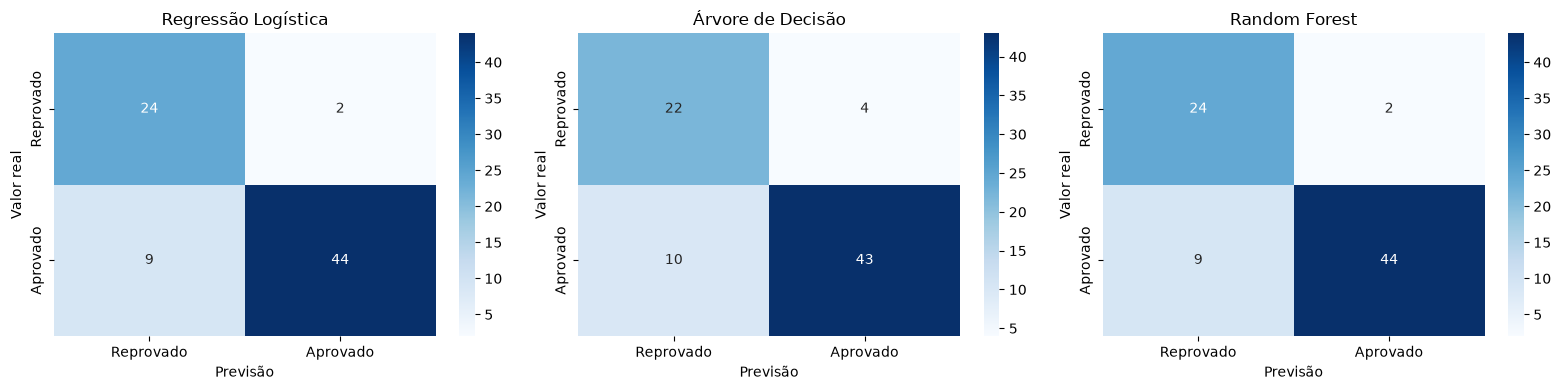

In [15]:
# Matriz de confusão 

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (nome, pipeline) in zip(axes, pipelines_treinados.items()):

    y_pred = pipeline.predict(X_teste)

    matriz = confusion_matrix(
        y_teste,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Reprovado", "Aprovado"],
        yticklabels=["Reprovado", "Aprovado"],
        ax=ax
    )

    ax.set_title(nome)
    ax.set_xlabel("Previsão")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

In [16]:
pred_logistica = pipelines_treinados[
    "Regressão Logística"
].predict(X_teste)

pred_random_forest = pipelines_treinados[
    "Random Forest"
].predict(X_teste)

print(
    "Previsões idênticas:",
    np.array_equal(pred_logistica, pred_random_forest)
)

Previsões idênticas: False


### Insights — Matrizes de Confusão

A análise das matrizes de confusão demonstrou que a Regressão Logística e a Random Forest apresentaram o melhor desempenho na identificação das classes, acertando 24 dos 26 estudantes reprovados e 44 dos 53 aprovados.

Ambos os modelos apresentaram apenas dois falsos negativos na classe dos reprovados, alcançando Recall de 92,31%. Entretanto, também classificaram nove estudantes aprovados incorretamente como reprovados.

A Árvore de Decisão apresentou maior quantidade de erros, identificando corretamente 22 estudantes reprovados e 43 aprovados.

Um aspecto interessante foi a igualdade das matrizes de confusão da Regressão Logística e da Random Forest. Apesar dos mesmos totais de acertos e erros, a comparação das previsões individuais demonstrou que os modelos não produziram classificações completamente idênticas.

**Conclusão:** a Regressão Logística e a Random Forest demonstraram maior capacidade de identificação dos estudantes reprovados neste conjunto de teste, enquanto a Árvore de Decisão apresentou desempenho inferior.

#### 7 - Importância das variáveis


In [17]:
# Recuperar o modelo Random Forest treinado
rf_pipeline = pipelines_treinados["Random Forest"]

# Recuperar o pré-processador ajustado
preprocessador_ajustado = rf_pipeline.named_steps["preprocessamento"]

# Recuperar o algoritmo treinado
rf_modelo = rf_pipeline.named_steps["modelo"]

# Obter os nomes das variáveis após o pré-processamento
nomes_features = preprocessador_ajustado.get_feature_names_out()

# Extrair a importância das variáveis
importancias = rf_modelo.feature_importances_

# Criar DataFrame
df_importancias = pd.DataFrame({
    "Variavel": nomes_features,
    "Importancia": importancias
})

# Ordenar da maior para a menor importância
df_importancias = df_importancias.sort_values(
    by="Importancia",
    ascending=False
).reset_index(drop=True)

df_importancias.head(20)

,Variavel,Importancia
0,num__G2,0.328668
1,num__G1,0.220301
2,num__failures,0.035700
3,num__absences,0.032589
4,num__goout,0.020149
5,num__health,0.019048
6,num__age,0.018786
7,num__Walc,0.015063
8,num__Fedu,0.014825
9,num__freetime,0.014377


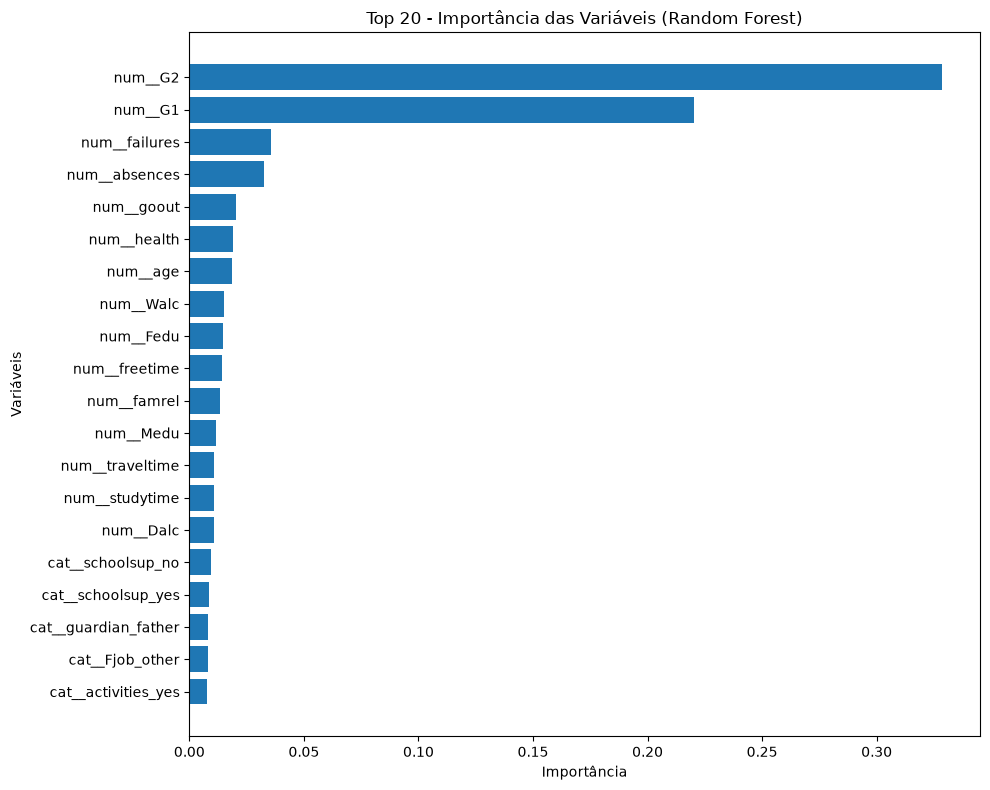

In [18]:
top_20 = df_importancias.head(20).sort_values(
    by="Importancia",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20["Variavel"],
    top_20["Importancia"]
)

plt.title("Top 20 - Importância das Variáveis (Random Forest)")
plt.xlabel("Importância")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

### Insights — Importância das Variáveis (Random Forest)

A análise da importância das variáveis revelou uma concentração expressiva do poder preditivo nas notas dos dois primeiros períodos escolares.

A variável G2 apresentou a maior importância, seguida por G1. Juntas, representam aproximadamente 55% da importância total do modelo, evidenciando a forte capacidade preditiva do histórico recente de desempenho acadêmico em relação à aprovação ou reprovação final.

Além das notas anteriores, destacaram-se `failures` (histórico de reprovações) e `absences` (quantidade de faltas), indicando que aspectos relacionados à trajetória e à frequência escolar também contribuem para as previsões.

Variáveis sociais, comportamentais e familiares apareceram com importâncias individuais menores, mas continuam relevantes para a investigação proposta.

**Principal conclusão:** a inclusão de G1 e G2 aumentou significativamente a capacidade preditiva do modelo. Entretanto, a importância apresentada pela Random Forest não representa causalidade e pode ser influenciada pela relação entre variáveis correlacionadas.

#### Coeficientes Regressão Logística

In [19]:
# Recuperar a Regressão Logística treinada
log_pipeline = pipelines_treinados["Regressão Logística"]

# Recuperar o pré-processador ajustado
log_preprocessador = log_pipeline.named_steps["preprocessamento"]

# Recuperar o modelo
log_modelo = log_pipeline.named_steps["modelo"]

# Obter nomes das variáveis transformadas
nomes_features_log = log_preprocessador.get_feature_names_out()

# Extrair coeficientes
coeficientes = log_modelo.coef_[0]

df_coeficientes = pd.DataFrame({
    "Variavel": nomes_features_log,
    "Coeficiente": coeficientes
})

# Ordenar pelos maiores valores absolutos
df_coeficientes["Importancia_Absoluta"] = (
    df_coeficientes["Coeficiente"].abs()
)

df_coeficientes = df_coeficientes.sort_values(
    by="Importancia_Absoluta",
    ascending=False
).reset_index(drop=True)

df_coeficientes.head(20)

,Variavel,Coeficiente,Importancia_Absoluta
0,num__G2,3.997626,3.997626
1,num__G1,1.939792,1.939792
2,cat__Fjob_other,0.910214,0.910214
3,num__Walc,0.777740,0.777740
4,num__age,-0.732887,0.732887
5,cat__school_MS,0.663571,0.663571
6,cat__school_GP,-0.663238,0.663238
7,cat__Mjob_services,0.548303,0.548303
8,num__famrel,0.521652,0.521652
9,cat__guardian_father,0.506470,0.506470


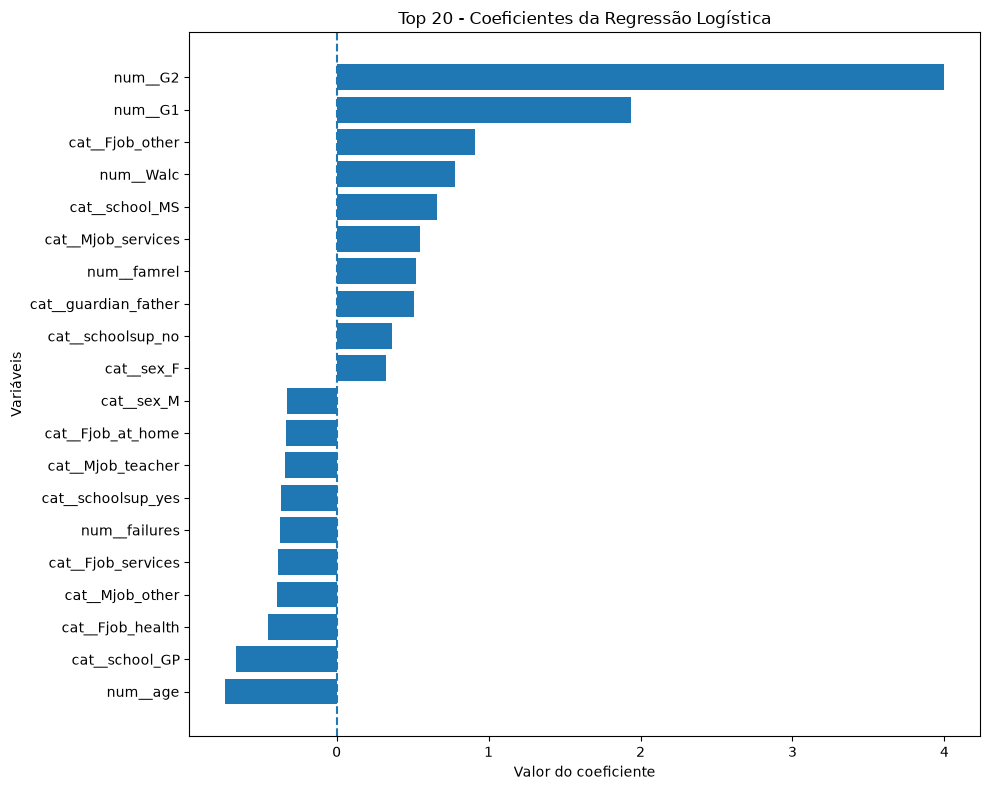

In [20]:
top_coeficientes = df_coeficientes.head(20).sort_values(
    by="Coeficiente"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_coeficientes["Variavel"],
    top_coeficientes["Coeficiente"]
)

plt.axvline(0, linestyle="--")

plt.title("Top 20 - Coeficientes da Regressão Logística")
plt.xlabel("Valor do coeficiente")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

### Insights — Coeficientes da Regressão Logística

A análise dos coeficientes da Regressão Logística apresentou resultados coerentes com a importância das variáveis identificada anteriormente pelo modelo Random Forest.

As notas G2 e G1 apresentaram os maiores coeficientes positivos, indicando uma associação positiva dessas variáveis com a previsão de aprovação pelo modelo. Esse resultado reforça a relevância do desempenho acadêmico nos períodos anteriores para a estimativa do resultado final.

Entre as demais variáveis, destacaram-se `failures` e `age`, que apresentaram coeficientes negativos, indicando associação com menores estimativas de aprovação pelo modelo. A variável `schoolsup_yes` também apresentou coeficiente negativo. Essas relações devem ser interpretadas considerando as demais variáveis presentes no modelo.

Outras características familiares e comportamentais, como ocupação dos pais, consumo de álcool aos finais de semana e responsável pelo estudante, também apareceram entre os coeficientes relevantes.

**Principal conclusão:** os resultados reforçam a importância do histórico acadêmico, especialmente G1 e G2, na previsão do desempenho final. As demais características pessoais, familiares e comportamentais também contribuem para as estimativas do modelo, mas seus coeficientes representam associações estatísticas, não relações de causa e efeito.

#### 8 - Avaliação com SHAP

In [21]:
import shap

# Recuperar o pipeline Random Forest treinado
rf_pipeline = pipelines_treinados["Random Forest"]

# Transformar os dados de teste com o pré-processador já ajustado
X_teste_transformado = (
    rf_pipeline.named_steps["preprocessamento"]
    .transform(X_teste)
)

# Recuperar os nomes das variáveis transformadas
nomes_features = (
    rf_pipeline.named_steps["preprocessamento"]
    .get_feature_names_out()
)

# Converter para DataFrame
X_teste_shap = pd.DataFrame(
    X_teste_transformado,
    columns=nomes_features,
    index=X_teste.index
)

print("Formato dos dados para SHAP:", X_teste_shap.shape)

Formato dos dados para SHAP: (79, 58)


In [22]:
# Recuperar o modelo Random Forest
rf_modelo = rf_pipeline.named_steps["modelo"]

# Criar explicador SHAP
explainer = shap.TreeExplainer(rf_modelo)

# Calcular valores SHAP
shap_values = explainer.shap_values(X_teste_shap)


print("Formato dos valores SHAP:", np.array(shap_values).shape)

print("Classes do modelo:", rf_modelo.classes_)

if isinstance(shap_values, list):
    for i, classe in enumerate(rf_modelo.classes_):
        print(
            f"Classe {classe}:",
            np.array(shap_values[i]).shape
        )
else:
    print("Formato SHAP:", np.array(shap_values).shape)

Formato dos valores SHAP: (79, 58, 2)
Classes do modelo: [0 1]
Formato SHAP: (79, 58, 2)


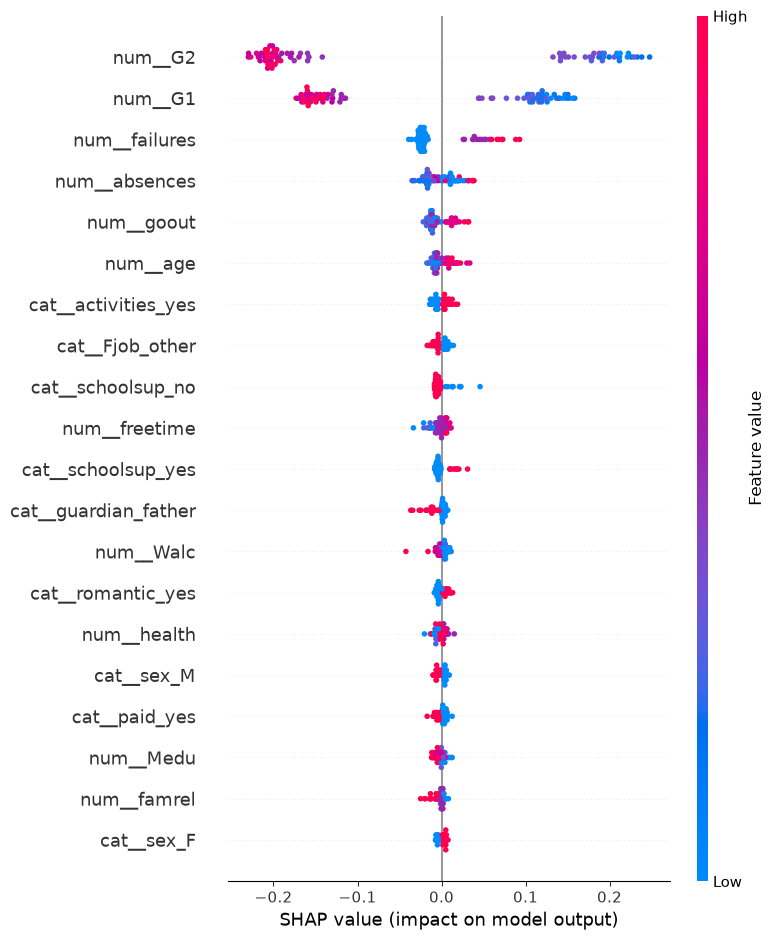

In [23]:
# Selecionar os valores SHAP da classe 0 (Reprovado)
shap_reprovado = shap_values[:, :, 0]

# Gráfico de impacto das variáveis
shap.summary_plot(
    shap_reprovado,
    X_teste_shap,
    max_display=20,
    show=True
)

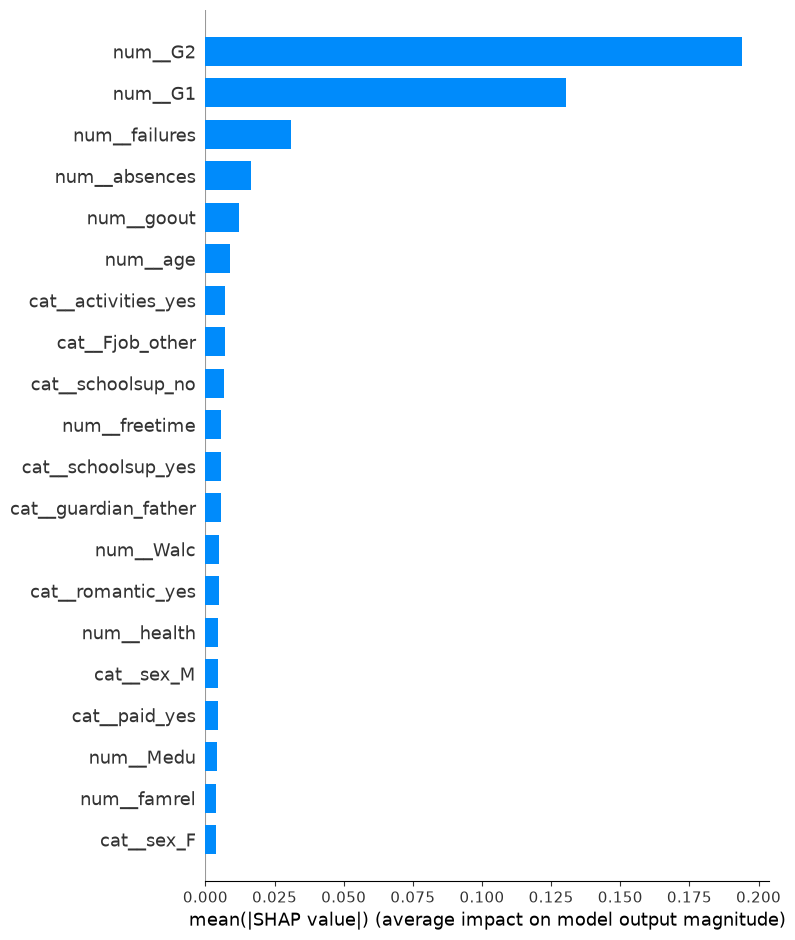

In [24]:
shap.summary_plot(
    shap_reprovado,
    X_teste_shap,
    plot_type="bar",
    max_display=20,
    show=True
)

### Insights — SHAP para a Classe Reprovado

A análise SHAP da classe 0 (Reprovado) confirmou a predominância das notas dos períodos anteriores na explicação das previsões da Random Forest.

As variáveis G2 e G1 apresentaram as maiores magnitudes de contribuição, demonstrando que notas mais baixas tendem a aumentar a saída do modelo associada à reprovação, enquanto notas mais altas tendem a reduzi-la.

A variável `failures`, referente ao histórico de reprovações anteriores, ocupou a terceira posição em importância global. Esse resultado reforça a relevância da trajetória acadêmica do estudante.

Também se destacaram `absences`, `goout` e `age`, indicando que o número de ausências escolares e características comportamentais e pessoais complementam as informações acadêmicas utilizadas na construção das previsões.

A variável `schoolsup_yes` apresentou contribuições positivas para a saída associada à reprovação em parte das observações. Esse resultado não deve ser interpretado como efeito negativo do apoio escolar, pois estudantes que enfrentam maiores dificuldades podem ser justamente aqueles que recebem esse suporte.

**Principal conclusão:** o SHAP confirmou que o desempenho acadêmico anterior é o principal elemento utilizado pelo modelo para identificar estudantes com maior probabilidade prevista de reprovação. As demais características complementam essa análise, mas apresentam influência individual consideravelmente menor.

Os resultados representam associações preditivas e não demonstram relações de causa e efeito.

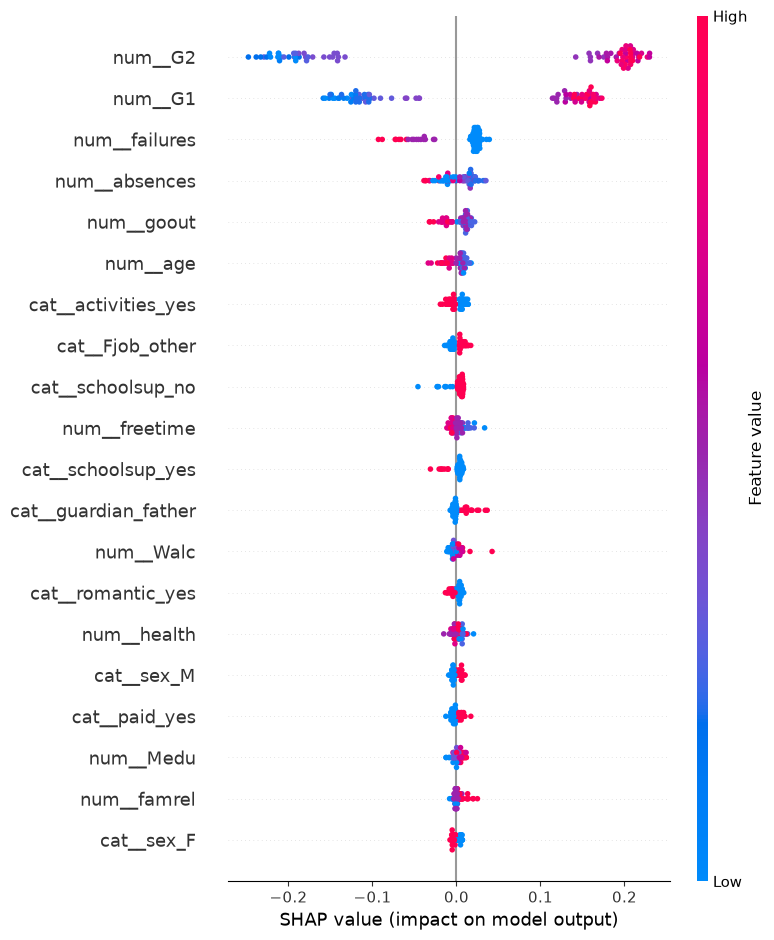

In [25]:
shap_aprovado = shap_values[:, :, 1]

shap.summary_plot(
    shap_aprovado,
    X_teste_shap,
    max_display=20,
    show=True
)

### Insights — SHAP para a Classe Aprovado

A análise SHAP da classe 1 (Aprovado) demonstrou que as notas G2 e G1 são os principais elementos associados às previsões positivas do modelo.

Observou-se que valores elevados de G2 e G1 apresentam contribuições positivas para a saída do modelo associada à classe Aprovado, enquanto valores baixos apresentam contribuições negativas. Esse comportamento indica que o histórico de desempenho acadêmico exerce forte influência nas previsões do modelo.

A variável `failures` também se destacou, apresentando comportamento inverso: valores elevados tendem a reduzir a saída associada à aprovação, reforçando a relevância do histórico acadêmico.

Outras características, como `absences`, `goout` e `age`, apresentaram contribuições de menor magnitude, mas com tendências que complementam a interpretação das previsões.

Entre as variáveis categóricas, destacaram-se `schoolsup_no` e `schoolsup_yes`, que apresentaram comportamentos opostos. Esse resultado deve ser interpretado com cautela, pois a necessidade de apoio escolar pode estar relacionada às dificuldades acadêmicas anteriores do estudante.

**Principal conclusão:** as explicações SHAP para a classe de aprovação confirmam os resultados encontrados na análise da classe de reprovação. O desempenho acadêmico anterior é o principal elemento utilizado pelo modelo para diferenciar os estudantes, enquanto as demais características oferecem informações complementares.

#### 9 - Comparação consolidada dos modelos

In [26]:
# Comparação consolidada dos resultados
# obtidos no conjunto de teste

comparacao_teste = df_resultados_teste[
    [
        "Modelo",
        "Accuracy",
        "F1 Macro",
        "Balanced Accuracy",
        "Precisão Reprovados",
        "Recall Reprovados",
        "F1 Reprovados"
    ]
].copy()

comparacao_teste.round(4)

,Modelo,Accuracy,F1 Macro,Balanced Accuracy,Precisão Reprovados,Recall Reprovados,F1 Reprovados
0,Regressão Logística,0.8608,0.8512,0.8766,0.7273,0.9231,0.8136
1,Árvore de Decisão,0.8228,0.8093,0.8287,0.6875,0.8462,0.7586
2,Random Forest,0.8608,0.8512,0.8766,0.7273,0.9231,0.8136


### Insights — Comparação dos Modelos no Conjunto de Teste

A avaliação dos três algoritmos demonstrou que a Regressão Logística e a Random Forest alcançaram os melhores resultados, apresentando igualdade nas métricas do conjunto de teste.

Ambos obtiveram Accuracy de 86,08%, F1 Macro de 85,12% e Balanced Accuracy de 87,66%.

Um dos resultados mais relevantes foi o Recall de 92,31% para a classe Reprovado, indicando que os modelos identificaram corretamente 24 dos 26 estudantes efetivamente reprovados.

A Árvore de Decisão apresentou resultados inferiores, com Accuracy de 82,28% e Recall de 84,62% para a classe Reprovado.

Considerando também os resultados da validação cruzada, a Random Forest será considerada a principal candidata à seleção final, enquanto a Regressão Logística permanecerá como modelo comparativo.

Os resultados indicam que a inclusão das notas G1 e G2 proporcionou um cenário de elevada capacidade preditiva, especialmente na identificação de estudantes reprovados.

In [27]:
# Identificar os modelos treinados
print("Modelos disponíveis:")

for nome in pipelines_treinados.keys():
    print("-", nome)

df_resultados_cv.round(4)

Modelos disponíveis:
- Regressão Logística
- Árvore de Decisão
- Random Forest


,Modelo,Accuracy,F1 Macro,Balanced Accuracy,Precisão Reprovados,Recall Reprovados,F1 Reprovados
0,Regressão Logística,0.9081,0.8981,0.9066,0.8372,0.9029,0.8665
1,Árvore de Decisão,0.9113,0.8986,0.8920,0.8982,0.8362,0.8631
2,Random Forest,0.9272,0.9194,0.9283,0.8618,0.9324,0.8945


### Seleção do Modelo Final

Com base principalmente no desempenho apresentado durante a validação cruzada, a Random Forest foi selecionada como modelo principal do projeto. A avaliação no conjunto de teste complementou essa análise, demonstrando resultados competitivos e equivalentes aos da Regressão Logística nas métricas gerais apresentadas.

Na validação cruzada, o algoritmo apresentou Accuracy de 92,72%, F1 Macro de 91,94% e Balanced Accuracy de 92,83%, superando os demais modelos nessas métricas.

Outro resultado relevante foi o Recall de 93,24% para a classe Reprovado, demonstrando uma boa capacidade de identificação dos estudantes pertencentes a essa categoria.

No conjunto de teste, a Random Forest também apresentou resultados competitivos, empatando com a Regressão Logística nas principais métricas gerais.

A escolha foi fundamentada principalmente no equilíbrio entre as classes e na capacidade de identificar estudantes reprovados, aspecto especialmente relevante para o objetivo do projeto.

In [28]:
import joblib
from pathlib import Path

# Selecionar o pipeline treinado da Random Forest
modelo_final = pipelines_treinados["Random Forest"]

# Caminho para salvar o modelo
caminho_modelo = Path("../models/modelo_final_com_g1_g2.joblib")

# Salvar o pipeline completo
joblib.dump(modelo_final, caminho_modelo)

print("Modelo salvo com sucesso!")
print("Caminho:", caminho_modelo)

Modelo salvo com sucesso!
Caminho: ..\models\modelo_final_com_g1_g2.joblib


In [29]:
# Carregar o modelo salvo
modelo_carregado = joblib.load(caminho_modelo)

# Realizar previsões no conjunto de teste
previsoes_teste = modelo_carregado.predict(X_teste)

print("Modelo carregado com sucesso!")
print("Total de previsões:", len(previsoes_teste))
print("Primeiras 10 previsões:", previsoes_teste[:10])

Modelo carregado com sucesso!
Total de previsões: 79
Primeiras 10 previsões: [1 0 1 1 1 1 1 0 1 1]


# 10 - Conclusão Geral

O projeto teve como objetivo desenvolver um modelo de classificação capaz de identificar estudantes com maior probabilidade de aprovação ou reprovação, utilizando características pessoais, familiares, sociais, comportamentais e escolares, além das notas dos dois primeiros períodos (G1 e G2).

Foram avaliados três algoritmos: Regressão Logística, Árvore de Decisão e Random Forest. A comparação considerou métricas como Accuracy, F1 Macro, Balanced Accuracy, Precisão, Recall e F1 da classe Reprovado.

A Random Forest foi selecionada como modelo final por apresentar os melhores resultados gerais na validação cruzada, alcançando 92,72% de Accuracy, 91,94% de F1 Macro e 92,83% de Balanced Accuracy.

No conjunto de teste, o modelo alcançou 86,08% de Accuracy e 92,31% de Recall para a classe Reprovado, identificando corretamente 24 dos 26 estudantes efetivamente reprovados.

As análises de importância das variáveis e os valores SHAP demonstraram que G2 e G1 são os atributos de maior contribuição para as previsões. Outras características, como histórico de reprovações, faltas, idade e comportamento social, também apresentaram relevância.

Dessa forma, o projeto demonstra o potencial da mineração de dados e do aprendizado de máquina para identificar padrões associados ao desempenho escolar e auxiliar na identificação de estudantes que podem necessitar de acompanhamento pedagógico.

# 11 - Limitações do Estudo

Apesar dos resultados positivos, algumas limitações devem ser consideradas na interpretação do projeto:

**1. Tamanho da base de dados**

O conjunto utilizado possui 395 registros. Embora seja suficiente para desenvolver os experimentos propostos, uma quantidade maior de observações poderia contribuir para avaliar a capacidade de generalização dos modelos.

**2. Dependência das notas anteriores**

As variáveis G1 e G2 apresentaram grande importância nas previsões. Isso significa que o modelo depende fortemente do desempenho acadêmico anterior. Portanto, sua utilização exige que essas notas já estejam disponíveis no momento da previsão.

**3. Limitação de generalização**

Os padrões identificados representam as características presentes na base analisada. Os resultados não garantem o mesmo desempenho em outras instituições, regiões ou conjuntos de estudantes.

**4. Interpretação das variáveis**

As análises de importância e SHAP identificam associações utilizadas pelo modelo para produzir suas previsões. Entretanto, não demonstram relações causais entre as características dos estudantes e os resultados acadêmicos.

**5. Possibilidade de aperfeiçoamento**

Os resultados podem variar conforme a composição dos dados, os parâmetros dos algoritmos e a estratégia de validação. Novos experimentos são necessários para avaliar a estabilidade do desempenho em diferentes amostras.

# 12 - Possibilidades de Melhoria e Trabalhos Futuros

A partir dos resultados obtidos, algumas melhorias podem ser consideradas para ampliar a qualidade e a aplicabilidade do projeto:

**1. Ampliação da base de dados**

Utilizar conjuntos de dados maiores e provenientes de diferentes instituições de ensino, permitindo avaliar a generalização dos modelos.

**2. Otimização de hiperparâmetros**

Explorar técnicas de busca de parâmetros, como GridSearchCV e RandomizedSearchCV, para investigar configurações que possam melhorar o desempenho da Random Forest.

**3. Avaliação em novas amostras**

Realizar testes com novos conjuntos de dados para verificar a estabilidade das métricas e a capacidade de generalização do modelo.

**4. Monitoramento de desempenho**

Acompanhar o comportamento do modelo ao longo do tempo, verificando possíveis mudanças nos padrões dos estudantes e a necessidade de retreinamento.

**5. Investigação de novas variáveis**

Avaliar a inclusão de informações adicionais sobre o contexto escolar, acompanhamento pedagógico e condições de aprendizagem, desde que disponíveis e adequadamente documentadas.

**6. Análise de equidade**

Investigar se o modelo apresenta diferenças relevantes de desempenho entre grupos de estudantes, evitando que suas previsões reforcem desigualdades existentes.

Essas possibilidades representam caminhos para evoluir o estudo, tornando a análise mais robusta, interpretável e aplicável a diferentes contextos educacionais.